In [12]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
DATA_DIR = Path(".")
DEFAULT_N_CHANNELS = 72

'''
file format expected :
- tones : mesure_[distance]m_[los/nlos]_[nbr_channel]_channel_[optional_tag].csv
- procedures : mesure_[distance]m_[los/nlos]_[nbr_channel]_channel_[optional_tag].csv
'''

FILENAME_RE = re.compile(
    r"^mesure_(?P<dist>\d+(?:_\d+)?)m_(?P<env>los|nlos)"
    r"(?:_(?P<n_channels>\d+)_channel)?"
    r"(?P<tag>(?:_[a-z]+)*?)"
    r"(?P<procedures>_procedures)?\.csv$"
)

def parse_filename(path: Path) -> dict | None:
    m = FILENAME_RE.match(path.name)
    if m is None:
        return None
    tag = m["tag"].lstrip("_")
    return {
        "file": path.name,
        "kind": "procedures" if m["procedures"] else "tones",
        "session": path.name.removesuffix(".csv").removesuffix("_procedures"),
        "true_distance_m": float(m["dist"].replace("_", ".")),
        "environment": m["env"].upper(),
        "n_channels": int(m["n_channels"]) if m["n_channels"] else DEFAULT_N_CHANNELS,
        "tag": tag,  # ex. "bis"
    }

files = pd.DataFrame([p for f in sorted(DATA_DIR.glob("mesure_*.csv")) if (p := parse_filename(f))])
unparsed = [f.name for f in DATA_DIR.glob("mesure_*.csv") if parse_filename(f) is None]
if unparsed:
    print("Unknown file format :", unparsed)

In [14]:
# Verify if pair tones and procedures files is present
pairing = files.pivot_table(index="session", columns="kind", values="file", aggfunc="first")
orphans = pairing[pairing.isna().any(axis=1)]
if len(orphans):
    print("Uncompleted session (tones or procedures file is missing) :")
    display(orphans)

Uncompleted session (tones or procedures file is missing) :


kind,procedures,tones
session,,
mesure_1_5m_los,mesure_1_5m_los_procedures.csv,NaN
mesure_1_5m_los_72_channel,NaN,mesure_1_5m_los_72_channel.csv


In [15]:
files.drop(columns="file").drop_duplicates("session").sort_values(["environment", "true_distance_m", "n_channels"]).reset_index(drop=True)

,kind,session,true_distance_m,environment,n_channels,tag
0,tones,mesure_0_5m_los_72_channel,0.5,LOS,72,
1,tones,mesure_1m_los_72_channel,1.0,LOS,72,
2,tones,mesure_1_5m_los_72_channel,1.5,LOS,72,
3,tones,mesure_1_5m_los_bis,1.5,LOS,72,bis
4,procedures,mesure_1_5m_los,1.5,LOS,72,
5,tones,mesure_2m_los_72_channel,2.0,LOS,72,
6,tones,mesure_2_5m_los_72_channel,2.5,LOS,72,
7,tones,mesure_3m_los_72_channel,3.0,LOS,72,
8,tones,mesure_3_5m_los_72_channel,3.5,LOS,72,
9,tones,mesure_4m_los_37_channel,4.0,LOS,37,


In [16]:
META_COLS = ["session", "true_distance_m", "environment", "n_channels", "tag"]

def load_all(kind: str) -> pd.DataFrame:
    frames = []
    for _, row in files[files["kind"] == kind].iterrows():
        df = pd.read_csv(DATA_DIR / row["file"])
        for c in META_COLS:
            df.insert(META_COLS.index(c), c, row[c])
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

procedures = load_all("procedures")
tones = load_all("tones")

METHODS = {
    "dist_ifft_m": "IFFT",
    "dist_phase_slope_m": "Phase slope",
    "dist_rtt_m": "RTT",
}


for col in METHODS:
    err = procedures[col] - procedures["true_distance_m"]
    procedures[col.replace("_m", "_error_m")] = err
    procedures[col.replace("_m", "_abs_error_m")] = err.abs()

procedures.to_csv("all_procedures.csv", index=False)
tones.to_csv("all_tones.csv", index=False)
print(f"all_procedures.csv : {len(procedures)} lignes, {procedures['session'].nunique()} sessions")
print(f"all_tones.csv      : {len(tones)} lignes")
procedures.head()

all_procedures.csv : 1141 lignes, 29 sessions
all_tones.csv      : 62500 lignes


,session,true_distance_m,environment,n_channels,tag,host_time,timestamp_ms,ranging_counter,ap,tone_quality,...,rssi_dbm,dist_ifft_m,dist_phase_slope_m,dist_rtt_m,dist_ifft_error_m,dist_ifft_abs_error_m,dist_phase_slope_error_m,dist_phase_slope_abs_error_m,dist_rtt_error_m,dist_rtt_abs_error_m
0,mesure_0_5m_los_72_channel,0.5,LOS,72,,2026-11-03T12:29:57.182,694752,1615,0,OK,...,-40.3,1.171,1.448,2.665,0.671,0.671,0.948,0.948,2.165,2.165
1,mesure_0_5m_los_72_channel,0.5,LOS,72,,2026-11-03T12:29:57.783,695353,1621,0,OK,...,-40.9,1.171,1.529,2.567,0.671,0.671,1.029,1.029,2.067,2.067
2,mesure_0_5m_los_72_channel,0.5,LOS,72,,2026-11-03T12:29:58.382,695952,1627,0,OK,...,-40.6,1.171,1.581,2.878,0.671,0.671,1.081,1.081,2.378,2.378
3,mesure_0_5m_los_72_channel,0.5,LOS,72,,2026-11-03T12:29:58.982,696553,1633,0,OK,...,-41.1,1.171,1.577,2.712,0.671,0.671,1.077,1.077,2.212,2.212
4,mesure_0_5m_los_72_channel,0.5,LOS,72,,2026-11-03T12:29:59.582,697152,1639,0,OK,...,-40.8,1.171,1.583,1.905,0.671,0.671,1.083,1.083,1.405,1.405


### Format long (le plus pratique à exploiter)

Une ligne par (procédure, méthode) : idéal pour `groupby`, filtres, et graphiques. Sauvé dans `all_procedures_long.csv`.

In [3]:
long = procedures.melt(
    id_vars=META_COLS + ["ranging_counter", "ap", "tone_quality", "rssi_dbm", "rtt_count"],
    value_vars=list(METHODS),
    var_name="method",
    value_name="estimated_distance_m",
)
long["method"] = long["method"].map(METHODS)
long["error_m"] = long["estimated_distance_m"] - long["true_distance_m"]
long["abs_error_m"] = long["error_m"].abs()
long.to_csv("all_procedures_long.csv", index=False)
long.head()

,session,true_distance_m,environment,n_channels,tag,ranging_counter,ap,tone_quality,rssi_dbm,rtt_count,method,estimated_distance_m,error_m,abs_error_m
0,mesure_0_5m_los_72_channel,0.5,LOS,72,,1615,0,OK,-40.3,18,IFFT,1.171,0.671,0.671
1,mesure_0_5m_los_72_channel,0.5,LOS,72,,1621,0,OK,-40.9,24,IFFT,1.171,0.671,0.671
2,mesure_0_5m_los_72_channel,0.5,LOS,72,,1627,0,OK,-40.6,20,IFFT,1.171,0.671,0.671
3,mesure_0_5m_los_72_channel,0.5,LOS,72,,1633,0,OK,-41.1,21,IFFT,1.171,0.671,0.671
4,mesure_0_5m_los_72_channel,0.5,LOS,72,,1639,0,OK,-40.8,19,IFFT,1.171,0.671,0.671


## Filtres d'analyse

- `ENVIRONMENT` : `"LOS"`, `"NLOS"` ou `None` (tout).
- `ONLY_OK_TONES` : pour IFFT / phase slope, ne garder que les procédures `tone_quality == "OK"` (RTT n'en dépend pas).
- `EXCLUDE_TAGS` : sessions à exclure (ex. `{"bis"}`).
- `DROP_ZERO_PHASE_SLOPE` : le phase slope renvoie exactement `0.000` quand il échoue (systématique à 15/37 canaux) ; on traite ces valeurs comme invalides.

In [4]:
ENVIRONMENT = "LOS"
ONLY_OK_TONES = True
EXCLUDE_TAGS: set[str] = set()
DROP_ZERO_PHASE_SLOPE = True

d = long.dropna(subset=["estimated_distance_m"]).copy()
if ENVIRONMENT:
    d = d[d["environment"] == ENVIRONMENT]
if EXCLUDE_TAGS:
    d = d[~d["tag"].isin(EXCLUDE_TAGS)]
if DROP_ZERO_PHASE_SLOPE:
    d = d[~((d["method"] == "Phase slope") & (d["estimated_distance_m"] == 0))]
if ONLY_OK_TONES:
    d = d[(d["method"] == "RTT") | (d["tone_quality"] == "OK")]

CHANNEL_COUNTS = sorted(d["n_channels"].unique())
# Palette catégorielle fixe (ordre stable : la couleur suit le nombre de canaux, pas son rang)
CH_COLORS = {15: "#2a78d6", 37: "#eb6834", 72: "#1baf7a"}
CH_MARKERS = {15: "s", 37: "^", 72: "o"}
METHOD_ORDER = list(METHODS.values())

print("Canaux présents :", CHANNEL_COUNTS)
pd.crosstab(d["true_distance_m"], d["n_channels"], values=d["session"], aggfunc="nunique").fillna(0).astype(int).rename_axis(
    index="distance réelle (m)", columns="nb canaux (sessions)")

Canaux présents : [np.int64(15), np.int64(37), np.int64(72)]


nb canaux (sessions),15,37,72
distance réelle (m),,,
0.5,0,0,1
1.0,0,0,1
1.5,0,0,2
2.0,0,0,1
2.5,0,0,1
3.0,0,0,1
3.5,0,0,1
4.0,0,1,3
4.5,0,0,1


## Statistiques par (méthode, nb canaux, distance réelle)

In [5]:
def q25(x): return x.quantile(0.25)
def q75(x): return x.quantile(0.75)

stats = (
    d.groupby(["method", "n_channels", "true_distance_m"])
    .agg(
        n=("estimated_distance_m", "size"),
        mean_est_m=("estimated_distance_m", "mean"),
        median_est_m=("estimated_distance_m", "median"),
        q25_est_m=("estimated_distance_m", q25),
        q75_est_m=("estimated_distance_m", q75),
        std_m=("estimated_distance_m", "std"),
        bias_m=("error_m", "mean"),
        mae_m=("abs_error_m", "mean"),
        rmse_m=("error_m", lambda e: np.sqrt(np.mean(e**2))),
    )
    .reset_index()
)

# Taux de procédures exploitables (avant filtrage NaN / qualité)
base = long if not ENVIRONMENT else long[long["environment"] == ENVIRONMENT]
ok = base["estimated_distance_m"].notna() & ((base["method"] == "RTT") | (base["tone_quality"] == "OK") | (not ONLY_OK_TONES))
if DROP_ZERO_PHASE_SLOPE:
    ok &= ~((base["method"] == "Phase slope") & (base["estimated_distance_m"] == 0))
valid = base.assign(valid=ok)
valid_rate = valid.groupby(["method", "n_channels", "true_distance_m"])["valid"].mean().rename("valid_rate").reset_index()
stats = stats.merge(valid_rate, on=["method", "n_channels", "true_distance_m"], how="left")

stats.to_csv("stats_by_method_channels_distance.csv", index=False)
stats.round(3)

,method,n_channels,true_distance_m,n,mean_est_m,median_est_m,q25_est_m,q75_est_m,std_m,bias_m,mae_m,rmse_m,valid_rate
0,IFFT,15,8.0,72,8.029,8.490,8.429,8.588,1.771,0.029,0.919,1.759,0.545
1,IFFT,37,4.0,38,3.375,4.074,1.704,4.183,1.188,-0.625,0.855,1.328,0.792
2,IFFT,37,5.0,57,5.801,5.940,5.886,5.992,0.626,0.801,0.993,1.014,1.000
3,IFFT,37,6.0,30,6.873,6.856,6.832,6.930,0.104,0.873,0.873,0.879,1.000
4,IFFT,37,7.0,33,7.075,7.389,7.324,7.464,1.341,0.075,0.692,1.323,1.000
5,IFFT,37,8.0,39,8.536,8.565,8.486,8.658,0.238,0.536,0.555,0.585,1.000
6,IFFT,72,0.5,18,1.223,1.171,1.171,1.171,0.120,0.723,0.723,0.732,1.000
7,IFFT,72,1.0,21,1.464,1.464,1.464,1.464,0.000,0.464,0.464,0.464,1.000
8,IFFT,72,1.5,65,2.562,2.669,2.525,2.710,0.361,1.062,1.107,1.121,1.000
9,IFFT,72,2.0,34,2.885,2.928,2.635,2.928,0.218,0.885,0.885,0.910,1.000


## Distance estimée vs distance réelle (médiane, barres = IQR)

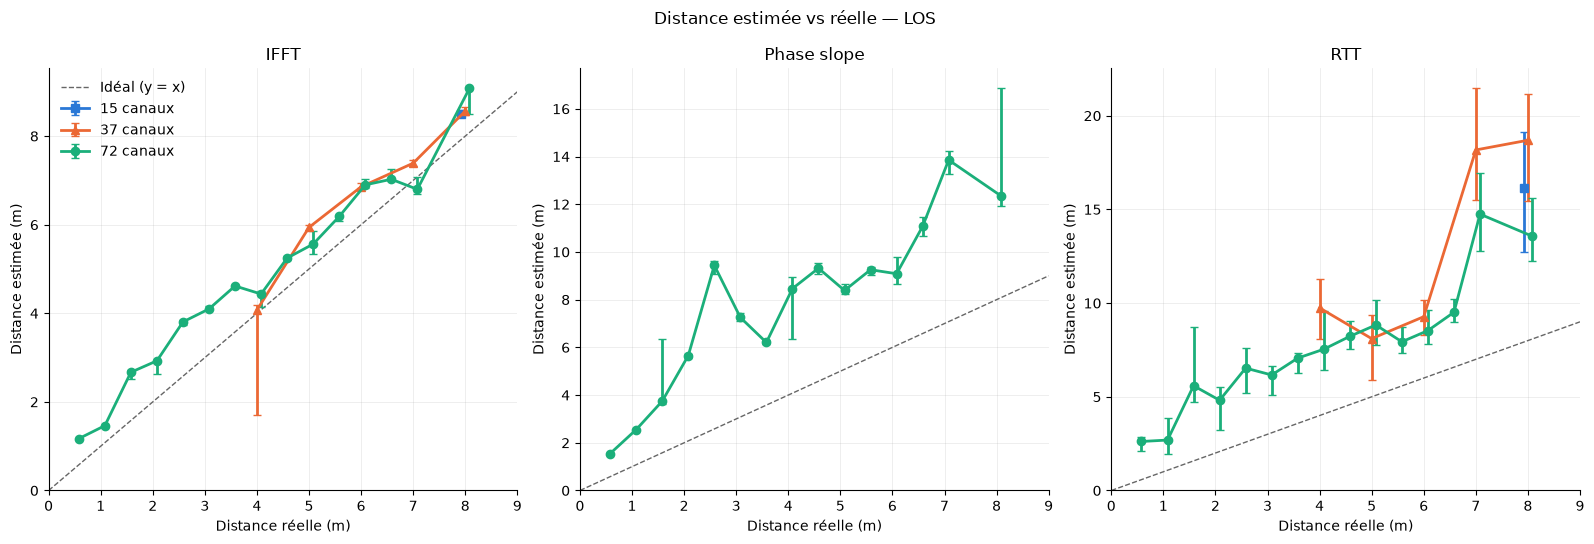

In [6]:
fig, axes = plt.subplots(1, len(METHOD_ORDER), figsize=(16, 5.5), sharex=True)
lim = [0, d["true_distance_m"].max() + 1]
for ax, method in zip(axes, METHOD_ORDER):
    ax.plot(lim, lim, color="0.4", ls="--", lw=1, label="Idéal (y = x)")
    for n_ch in CHANNEL_COUNTS:
        s = stats[(stats["method"] == method) & (stats["n_channels"] == n_ch)].sort_values("true_distance_m")
        if s.empty:
            continue
        x = s["true_distance_m"] + (CHANNEL_COUNTS.index(n_ch) - 1) * 0.08  # léger décalage pour lisibilité
        ax.errorbar(
            x, s["median_est_m"],
            yerr=[s["median_est_m"] - s["q25_est_m"], s["q75_est_m"] - s["median_est_m"]],
            color=CH_COLORS.get(n_ch), marker=CH_MARKERS.get(n_ch, "o"), ms=6, lw=2, capsize=3,
            label=f"{n_ch} canaux",
        )
    ax.set_title(method)
    ax.set_xlabel("Distance réelle (m)")
    ax.set_xlim(lim); ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
for ax in axes: ax.set_ylabel("Distance estimée (m)")
axes[0].legend(frameon=False)
fig.suptitle(f"Distance estimée vs réelle — {ENVIRONMENT or 'tous environnements'}")
fig.tight_layout()
plt.show()

## Erreur (estimé − réel) en fonction de la distance réelle

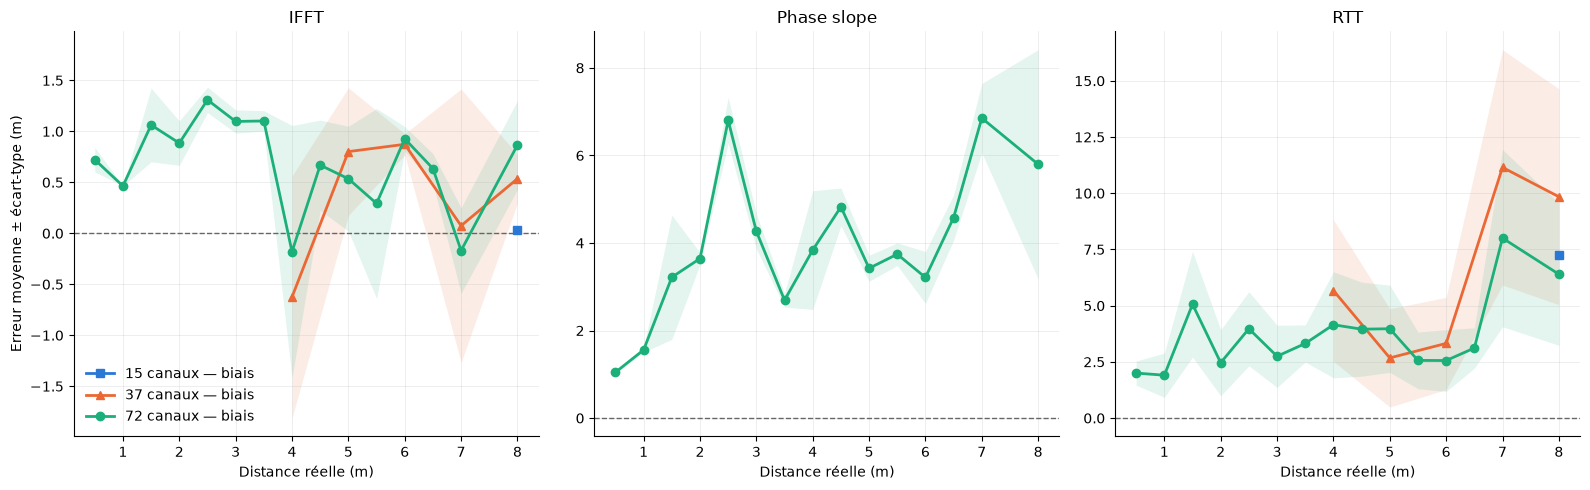

In [7]:
fig, axes = plt.subplots(1, len(METHOD_ORDER), figsize=(16, 5), sharex=True)
for ax, method in zip(axes, METHOD_ORDER):
    ax.axhline(0, color="0.4", ls="--", lw=1)
    for n_ch in CHANNEL_COUNTS:
        s = stats[(stats["method"] == method) & (stats["n_channels"] == n_ch)].sort_values("true_distance_m")
        if s.empty:
            continue
        ax.plot(s["true_distance_m"], s["bias_m"], color=CH_COLORS.get(n_ch), marker=CH_MARKERS.get(n_ch, "o"),
                ms=6, lw=2, label=f"{n_ch} canaux — biais")
        ax.fill_between(s["true_distance_m"], s["bias_m"] - s["std_m"], s["bias_m"] + s["std_m"],
                        color=CH_COLORS.get(n_ch), alpha=0.12, lw=0)
    ax.set_title(method)
    ax.set_xlabel("Distance réelle (m)")
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Erreur moyenne ± écart-type (m)")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

## Comparaison directe des nombres de canaux

Uniquement aux distances où **au moins deux** configurations de canaux ont été mesurées.

Distances comparables : [4.0, 5.0, 6.0, 7.0, 8.0]


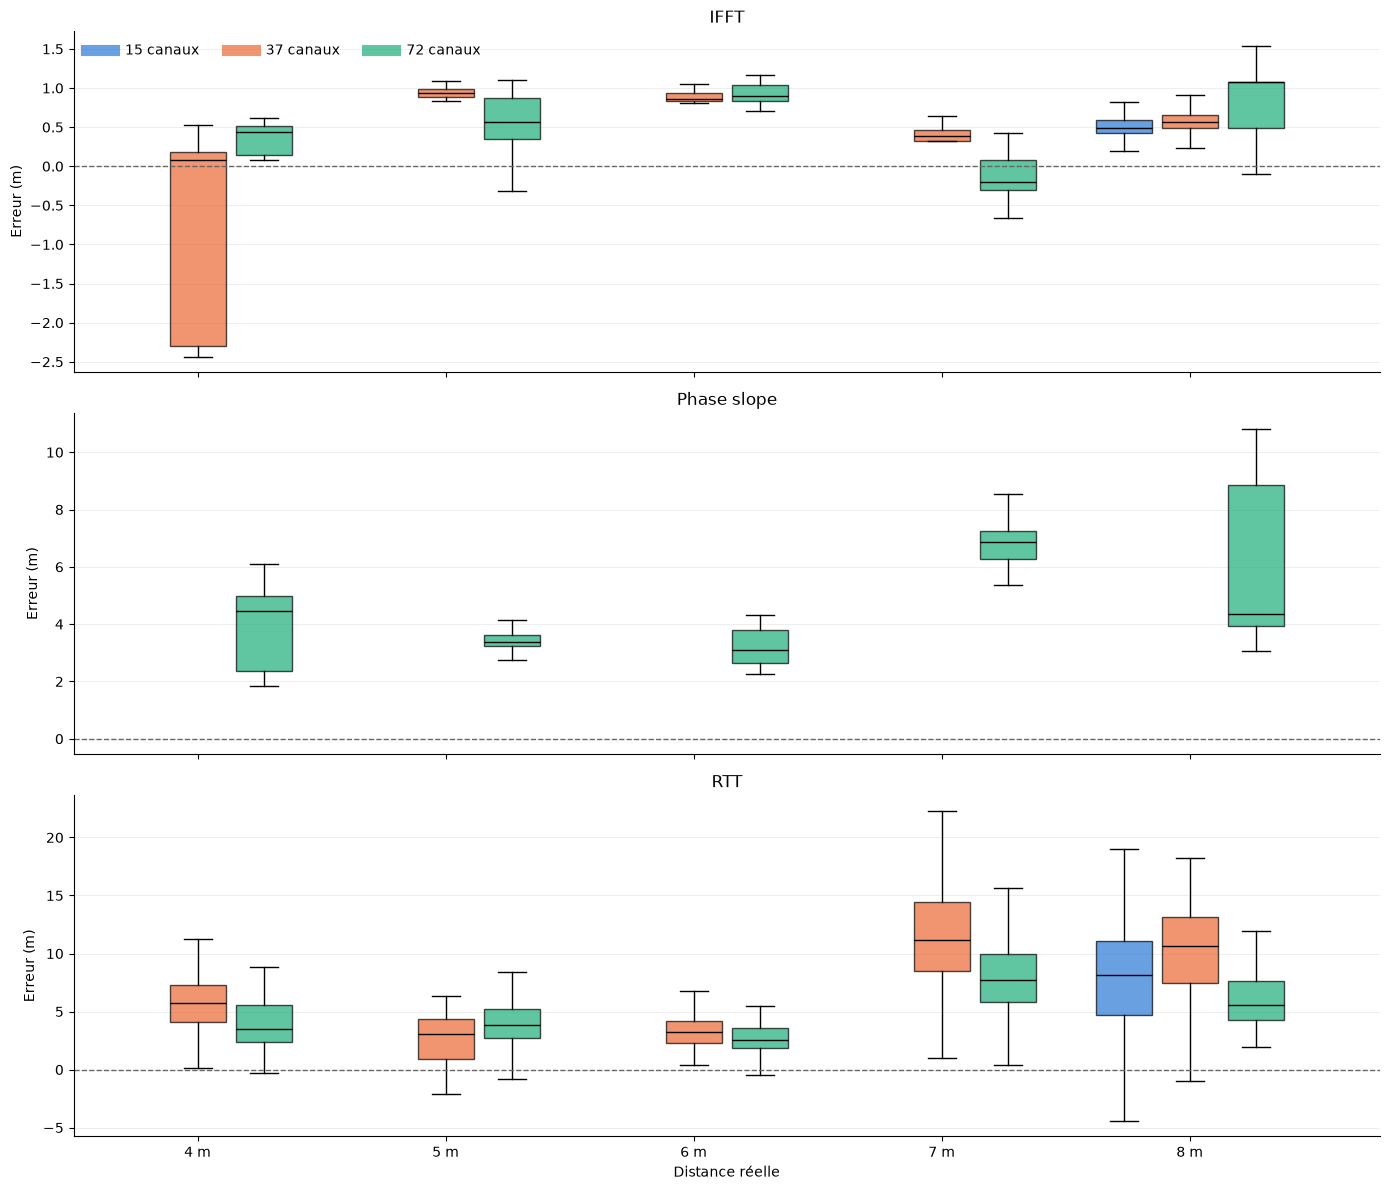

In [8]:
multi = d.groupby("true_distance_m")["n_channels"].nunique()
common_dists = multi[multi >= 2].index.tolist()
dc = d[d["true_distance_m"].isin(common_dists)]
print("Distances comparables :", common_dists)

fig, axes = plt.subplots(len(METHOD_ORDER), 1, figsize=(14, 4 * len(METHOD_ORDER)), sharex=True)
width = 0.8 / len(CHANNEL_COUNTS)
for ax, method in zip(axes, METHOD_ORDER):
    for i, n_ch in enumerate(CHANNEL_COUNTS):
        data = [dc[(dc["method"] == method) & (dc["n_channels"] == n_ch) & (dc["true_distance_m"] == t)]["error_m"].values
                for t in common_dists]
        pos = np.arange(len(common_dists)) + (i - (len(CHANNEL_COUNTS) - 1) / 2) * width
        keep = [k for k, v in enumerate(data) if len(v)]
        if not keep:
            continue
        bp = ax.boxplot([data[k] for k in keep], positions=pos[keep], widths=width * 0.85,
                        patch_artist=True, showfliers=False, medianprops=dict(color="black"))
        for b in bp["boxes"]:
            b.set_facecolor(CH_COLORS.get(n_ch)); b.set_alpha(0.7)
        ax.plot([], [], color=CH_COLORS.get(n_ch), lw=8, alpha=0.7, label=f"{n_ch} canaux")
    ax.axhline(0, color="0.4", ls="--", lw=1)
    ax.set_title(method); ax.set_ylabel("Erreur (m)")
    ax.grid(alpha=0.3, axis="y"); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, ncol=len(CHANNEL_COUNTS))
axes[-1].set_xticks(range(len(common_dists)), [f"{t:g} m" for t in common_dists])
axes[-1].set_xlabel("Distance réelle")
fig.tight_layout()
plt.show()

## Synthèse globale par méthode et nombre de canaux (distances communes)

In [9]:
summary = (
    dc.groupby(["method", "n_channels"])
    .agg(n=("error_m", "size"),
         bias_m=("error_m", "mean"),
         std_m=("error_m", "std"),
         mae_m=("abs_error_m", "mean"),
         median_abs_err_m=("abs_error_m", "median"),
         rmse_m=("error_m", lambda e: np.sqrt(np.mean(e**2))))
    .round(3)
)
summary

n  bias_m  std_m  mae_m  median_abs_err_m  rmse_m
method      n_channels                                                     
IFFT        15           72   0.029  1.771  0.919             0.528   1.759
            37          197   0.363  0.995  0.811             0.825   1.056
            72          412   0.470  0.793  0.758             0.728   0.921
Phase slope 72          428   4.773  2.143  4.773             4.088   5.231
RTT         15          132   7.245  5.351  8.059             8.124   8.995
            37          207   6.166  4.879  6.281             5.135   7.855
            72          428   5.190  3.305  5.209             4.480   6.151

## Pistes d'exploitation de `all_procedures_long.csv`

```python
df = pd.read_csv("all_procedures_long.csv")
df.query("method == 'IFFT' and n_channels == 37 and tone_quality == 'OK'")
df.pivot_table(index="true_distance_m", columns=["method", "n_channels"], values="abs_error_m", aggfunc="median")
```